# 1. Análisis Exploratorio de Datos (EDA) - Reseñas en Español

En este cuaderno realizamos el **Análisis Exploratorio de Datos (EDA)** sobre nuestro conjunto de datos de reseñas de restaurantes y hoteles en español (`data/resenas.csv`).

El dataset contiene **1.200 opiniones realistas** clasificadas en dos sentimientos (`positivo` y `negativo`), recopiladas de distintos canales digitales. Este análisis inicial nos permitirá comprender la estructura de la tabla, verificar la ausencia de datos nulos, comprobar el balance de clases, analizar la longitud de las reseñas y observar las palabras más repetidas en crudo para justificar la construcción de nuestro pipeline de Procesamiento de Lenguaje Natural (NLP).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Cargamos el archivo CSV de reseñas utilizando codificación UTF-8 para preservar tildes y caracteres del español
df = pd.read_csv('../data/resenas.csv', encoding='utf-8')

# Mostramos las dimensiones del conjunto de datos (cantidad de filas y columnas)
print("Filas y columnas:", df.shape)

# Imprimimos la lista oficial con los nombres de las columnas
print("Columnas del dataset:", list(df.columns))

# Visualizamos las primeras 5 filas para inspeccionar el contenido
df.head(5)

Filas y columnas: (1200, 4)
Columnas del dataset: ['id', 'texto', 'etiqueta', 'canal']


,id,texto,etiqueta,canal
0,1,"Pésima gestión y trato grosero del personal, h...",negativo,redes_sociales
1,2,"SÚPER RECOMENDADO AL 100%, felicitaciones a @h...",positivo,google_maps
2,3,"Una experiencia inolvidable en el hotel, pagam...",positivo,tripadvisor
3,4,¡Increíble experiencia en este lugar! reservam...,positivo,web
4,5,"Pésimo servicio, el aire acondicionado no func...",negativo,app_movil


In [3]:
# Verificamos cuántos valores nulos o vacíos existen por cada columna
# Es fundamental validar datos vacíos antes de entrenar un modelo porque los textos faltantes
# provocan errores en la vectorización (TF-IDF) y las etiquetas nulas impiden el aprendizaje supervisado.
conteo_nulos = df.isna().sum()
print("Conteo de valores nulos por columna:")
print(conteo_nulos)

Conteo de valores nulos por columna:
id          0
texto       0
etiqueta    0
canal       0
dtype: int64


Distribución de etiquetas:
etiqueta
negativo    600
positivo    600
Name: count, dtype: int64


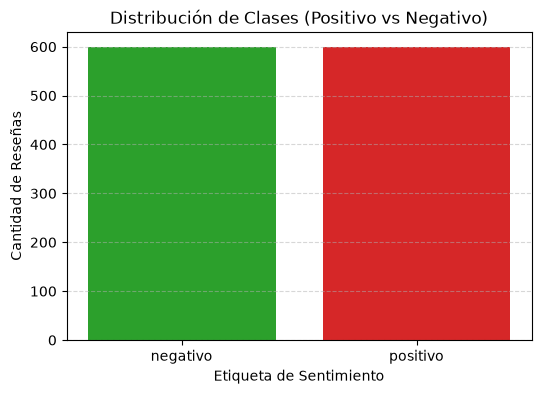

In [4]:
# Contamos cuántos registros existen para cada clase ('positivo' y 'negativo')
conteo_clases = df['etiqueta'].value_counts()
print("Distribución de etiquetas:")
print(conteo_clases)

# Graficamos la distribución de clases para confirmar visualmente que el dataset está balanceado
plt.figure(figsize=(6, 4))
plt.bar(conteo_clases.index, conteo_clases.values, color=['#2ca02c', '#d62728'])
plt.title('Distribución de Clases (Positivo vs Negativo)')
plt.xlabel('Etiqueta de Sentimiento')
plt.ylabel('Cantidad de Reseñas')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Resumen estadístico de la cantidad de palabras por reseña:
count    1200.000000
mean       27.885000
std         4.713133
min        15.000000
25%        25.000000
50%        27.000000
75%        32.000000
max        42.000000
Name: cantidad_palabras, dtype: float64


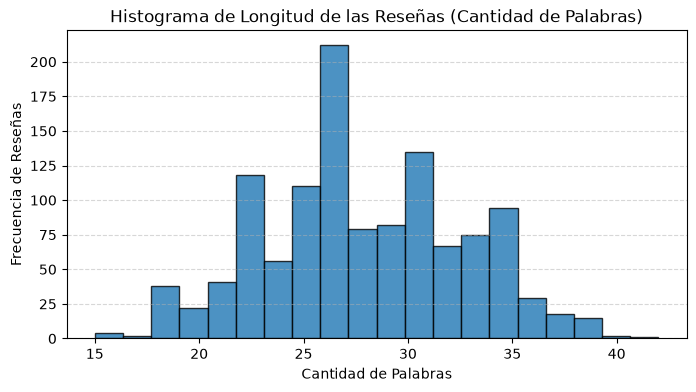

In [5]:
# Calculamos la cantidad de palabras de cada reseña separando por espacios
df['cantidad_palabras'] = df['texto'].str.split().str.len()

print("Resumen estadístico de la cantidad de palabras por reseña:")
print(df['cantidad_palabras'].describe())

# Dibujamos un histograma para observar la distribución de la longitud de los mensajes
plt.figure(figsize=(8, 4))
plt.hist(df['cantidad_palabras'], bins=20, color='#1f77b4', edgecolor='black', alpha=0.8)
plt.title('Histograma de Longitud de las Reseñas (Cantidad de Palabras)')
plt.xlabel('Cantidad de Palabras')
plt.ylabel('Frecuencia de Reseñas')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Las 20 palabras más repetidas en crudo:
texto
y             1827
el            1118
la            1042
de             964
en             893
con            571
por            525
no             477
bolivianos     419
a              395
este           352
muy            336
horas          335
No             302
fue            256
nos            249
para           248
Pagamos        232
Más            232
detalles       232
Name: count, dtype: int64


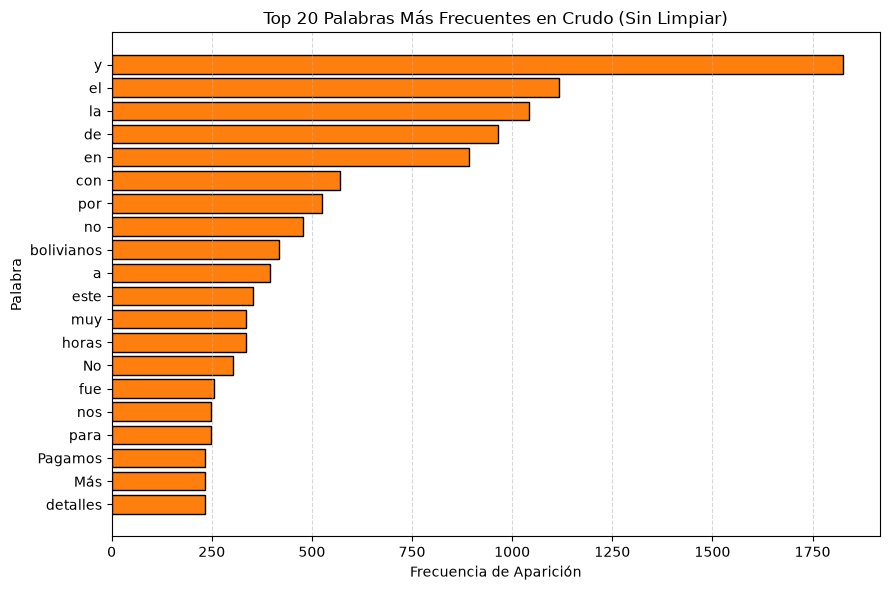

In [6]:
# Unimos todas las palabras en crudo (sin limpiar) para contar las 20 más repetidas
# Nota: Como el texto aún no pasó por limpieza, veremos principalmente palabras conectoras (stop words)
# como 'de', 'la', 'el', 'que', 'y', 'en', las cuales no aportan sentimiento por sí solas.
# Esto justifica plenamente construir nuestro pipeline de limpieza NLP en la siguiente etapa.
todas_las_palabras = df['texto'].str.split().explode()
palabras_frecuentes = todas_las_palabras.value_counts().head(20)

print("Las 20 palabras más repetidas en crudo:")
print(palabras_frecuentes)

# Mostramos las 20 palabras más frecuentes en un gráfico de barras horizontal
plt.figure(figsize=(9, 6))
plt.barh(palabras_frecuentes.index[::-1], palabras_frecuentes.values[::-1], color='#ff7f0e', edgecolor='black')
plt.title('Top 20 Palabras Más Frecuentes en Crudo (Sin Limpiar)')
plt.xlabel('Frecuencia de Aparición')
plt.ylabel('Palabra')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()